In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [60]:
df = pd.read_csv('./datasets/BreastCancer.csv')

- **Id:** Unique identification number assigned to each cell sample.
- **Cl.thickness:** Measures the thickness of the cell clumps, indicating how thick the grouped cells are.
- **Cell.size:** Measures the uniformity of cell size, where variation in size may indicate abnormality.
- **Cell.shape:** Measures the uniformity of cell shape, where irregular shapes may indicate abnormality.
- **Marg.adhesion:** Measures how strongly cells adhere to each other, with reduced adhesion potentially indicating malignancy.
- **Epith.c.size:** Measures the size of epithelial cells, where enlarged cells may indicate abnormal growth.
- **Bare.nuclei:** Measures the number of nuclei that are not surrounded by cytoplasm.
- **Bl.cromatin:** Evaluates the texture and appearance of chromatin (the material inside the cell nucleus).
- **Normal.nucleoli:** Measures the prominence and appearance of nucleoli inside the cell nucleus.
- **Mitoses:** Measures the number of cells undergoing mitosis (cell division).
- **Class:** Indicates the diagnosis category: benign (non-cancerous) or malignant (cancerous).

In [61]:
df.head()

,Id,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1.0,3,1,1,0
1,1002945,5,4,4,5,7,10.0,3,2,1,0
2,1015425,3,1,1,1,2,2.0,3,1,1,0
3,1016277,6,8,8,1,3,4.0,3,7,1,0
4,1017023,4,1,1,3,2,1.0,3,1,1,0


## `Understand whether your dataset is balanced.`

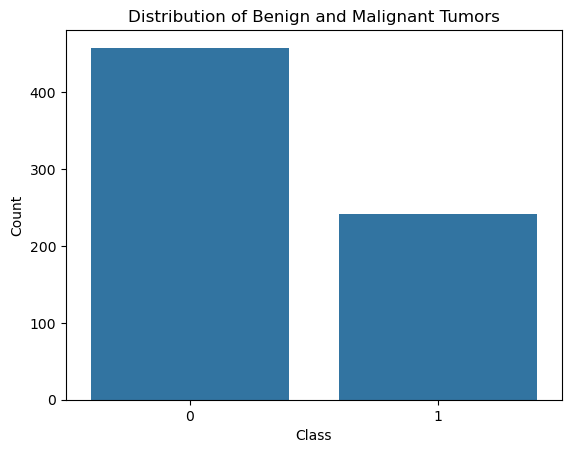

In [62]:
sns.countplot(data=df, x='Class')

plt.title('Distribution of Benign and Malignant Tumors')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

<span style="color: blue;"> Skewness </span> `is a statistical measure that describes the asymmetry of a data distribution. It indicates whether the data is evenly distributed around the mean or whether it has a longer tail on one side. There are three types of skewness: **Positive skewness (right-skewed)** occurs when the distribution has a longer tail on the right side, meaning most values are concentrated on the left; **Negative skewness (left-skewed)** occurs when the distribution has a longer tail on the left side, meaning most values are concentrated on the right; and **Zero skewness (symmetric distribution)** occurs when the data is approximately symmetrical around its center. Skewness is important in data analysis because highly skewed data can affect statistical methods and machine learning models, so transformations such as logarithmic or square root transformations may sometimes be useful to make the distribution more symmetric.`

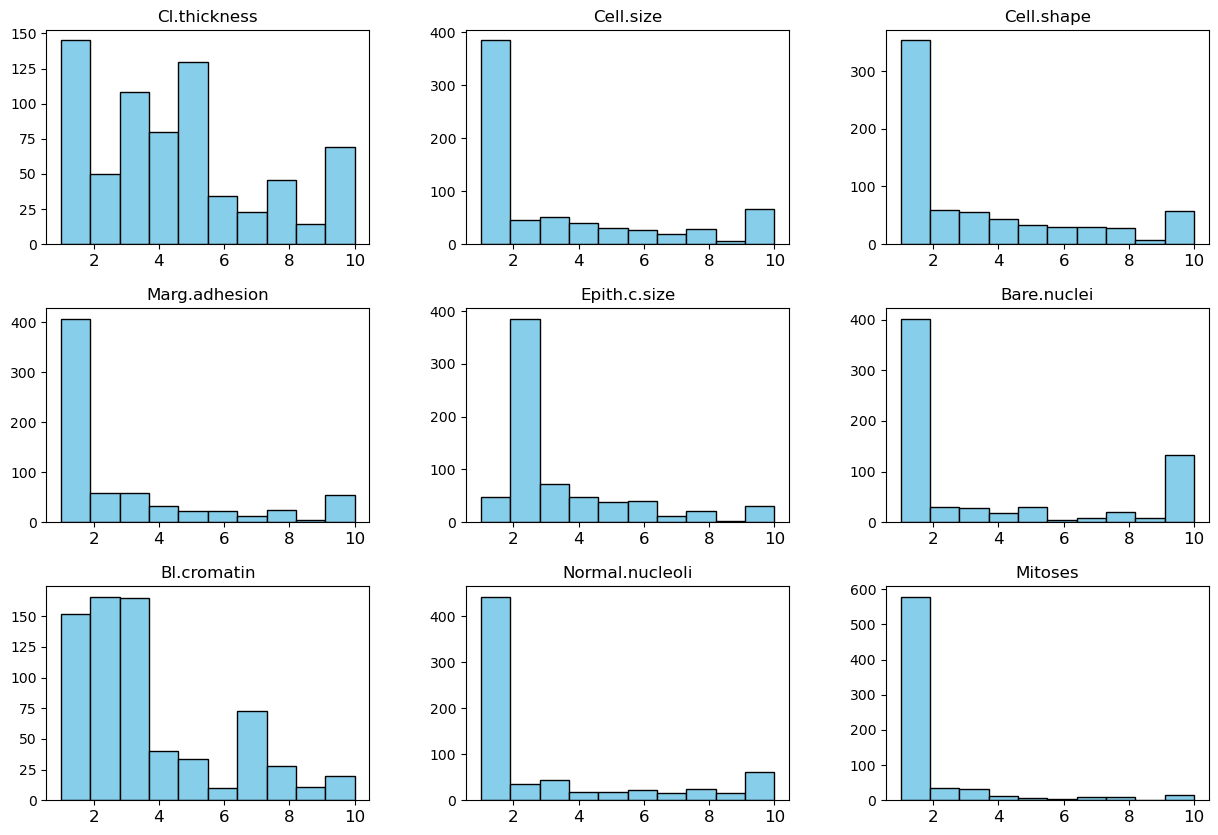

In [63]:
features = df.drop(columns=['Id', 'Class']).columns

df[features].hist(
    figsize=(15, 10),
    bins=10,
    edgecolor='black',
    grid=False,
    xlabelsize=12,
    ylabelsize=10,
    color='skyblue'

)

plt.show()

<span style="color: blue;"> Imputing </span> `in data analysis means replacing missing values (NaN values) in a dataset with suitable estimated or calculated values instead of deleting the rows or columns containing them.`

## `which features contain na values`

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Id               699 non-null    int64  
 1   Cl.thickness     699 non-null    int64  
 2   Cell.size        699 non-null    int64  
 3   Cell.shape       699 non-null    int64  
 4   Marg.adhesion    699 non-null    int64  
 5   Epith.c.size     699 non-null    int64  
 6   Bare.nuclei      683 non-null    float64
 7   Bl.cromatin      699 non-null    int64  
 8   Normal.nucleoli  699 non-null    int64  
 9   Mitoses          699 non-null    int64  
 10  Class            699 non-null    int64  
dtypes: float64(1), int64(10)
memory usage: 60.2 KB


## `Fill Bare.uclei with median`

In [65]:
target = df['Class']
df = df.drop(columns=['Id', 'Class'])

In [66]:
df['Bare.nuclei'] = df['Bare.nuclei'].fillna(df['Bare.nuclei'].median())

In [67]:
df.isna().sum()

Cl.thickness       0
Cell.size          0
Cell.shape         0
Marg.adhesion      0
Epith.c.size       0
Bare.nuclei        0
Bl.cromatin        0
Normal.nucleoli    0
Mitoses            0
dtype: int64

<span style="color: blue;"> Feature scaling</span>  puts all numeric features on a comparable range so that no feature dominates just because its numbers are bigger. For example, if one column is age (20 to 80) and another is income (20,000 to 200,000), distance-based algorithms such as KNN, SVM and k-means, and gradient-based models such as neural networks and logistic regression, will treat income as far more important simply because of its scale. Scaling also makes gradient descent converge faster and more stably, because the loss surface becomes more even and the learning rate works well for all weights.

## Min-Max Normalization

**Formula:** `x' = (x - min) / (max - min)`, which rescales values to the range 0 to 1.

**Used where:** It suits data with known, bounded ranges and no strong outliers, such as image pixels, and algorithms like neural networks and KNN that expect inputs in a fixed range. It is sensitive to outliers, because one extreme value squeezes all the other values into a tiny interval.

## Standardization (Z-score)

**Formula:** `x' = (x - mean) / std`, which gives mean 0 and standard deviation 1 (the values are not limited to a fixed range).

**Used where:** It suits data that is roughly bell-shaped or contains outliers, and algorithms that assume centered data, such as logistic regression, SVM, PCA and linear models in general. It is the safer default when you are unsure which one to pick.

In [ ]:
cols = df.select_dtypes(include='number').columns
df[cols] = df[cols].apply(lambda x: (x - x.mean()) / x.std())
df[cols]

,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses
0,0.206788,-0.699494,-0.742767,-0.632794,-0.549168,-0.686488,-0.179534,-0.611387,-0.343666
1,0.206788,0.283642,0.266684,0.768071,1.708882,1.798376,-0.179534,-0.283909,-0.343666
2,-0.503505,-0.699494,-0.742767,-0.632794,-0.549168,-0.410392,-0.179534,-0.611387,-0.343666
3,0.561934,1.594490,1.612618,-0.632794,-0.097558,0.141800,-0.179534,1.353485,-0.343666
4,-0.148359,-0.699494,-0.742767,0.067638,-0.549168,-0.686488,-0.179534,-0.611387,-0.343666
...,...,...,...,...,...,...,...,...,...
694,-0.503505,-0.699494,-0.742767,-0.632794,-0.097558,-0.410392,-0.999756,-0.611387,-0.343666
695,-0.858651,-0.699494,-0.742767,-0.632794,-0.549168,-0.686488,-0.999756,-0.611387,-0.343666
696,0.206788,2.249915,2.285586,0.067638,1.708882,-0.134296,1.871021,2.335921,0.239398
697,-0.148359,1.594490,0.939651,0.417854,-0.097558,0.141800,2.691243,1.026006,-0.343666


The <span style="color: blue;"> **dot product** </span>is a mathematical operation that takes two vectors (lists of numbers), multiplies their corresponding elements, and adds the results together to produce a single number (scalar). For example, if A = [2, 3, 4] and B = [5, 6, 7], their dot product is (2 × 5) + (3 × 6) + (4 × 7) = 56.

The dot product is widely used in Machine Learning because it allows us to calculate **weighted sums and make predictions**. For example, in Linear Regression, a prediction is calculated by multiplying each input feature by its corresponding weight and adding the results together: y = w · x + b. It is also used in neural networks, where each neuron multiplies its inputs by weights, adds them together, and passes the result through an activation function.

Another important application is measuring similarity between vectors, which is useful in recommendation systems and search engines. The dot product is also a fundamental part of matrix multiplication, which allows machine learning models to perform many calculations efficiently. In short, the dot product is important because it helps models combine information, calculate predictions, and compare data.

# Convergent and Divergent Functions

## Convergent function

A function **converges** when its values approach one specific finite number as the input moves toward some point (often as x → ∞). That number is called the **limit**.

**Example:** f(x) = 1/x

As x gets larger (10, 100, 1000, ...), f(x) gets closer to 0. The limit is 0, so the function is convergent.

## Divergent function

A function **diverges** when its values do not settle on a single finite number. There are three common cases:

| Case | Example | What happens |
|---|---|---|
| Grows without bound | f(x) = x² | Values go to +∞ |
| Falls without bound | f(x) = −x | Values go to −∞ |
| Oscillates | f(x) = sin(x) | Values keep swinging between −1 and 1, never settling |

## Quick comparison

| | Convergent | Divergent |
|---|---|---|
| Limit | Exists and is finite | Does not exist or is infinite |
| Behavior | Settles toward one value | Grows, falls, or oscillates forever |
| Example | 1/x → 0 | x² → ∞ |

## Why this matters in data analysis and machine learning

Training a model with gradient descent produces a loss value after each step, and this sequence of losses can either converge or diverge.

- **Convergence:** the loss decreases and flattens out near a minimum. The model has finished learning. This is the healthy case.
- **Divergence:** the loss grows, jumps around, or becomes `NaN`. A common cause is a learning rate that is too high, so each step overshoots the minimum.

**Simple example:** minimizing f(w) = w² with gradient descent, starting at w = 1.

- Learning rate 0.1: w = 1 → 0.8 → 0.64 → 0.512 → ... → 0 (**converges**)
- Learning rate 1.1: w = 1 → −1.2 → 1.44 → −1.73 → ... (**diverges**, the values keep growing)

Scaling features (for example min-max or standardization) helps gradient descent converge faster and more stably.

## Key takeaway

> Convergent = settles on a finite value. Divergent = it does not.

In [74]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1) Convergent function: f(x) = 1/x
x = np.linspace(1, 50, 200)
ax = axes[0, 0]
ax.plot(x, 1 / x, color="tab:blue")
ax.axhline(0, color="gray", linestyle="--", label="limit = 0")
ax.set_title("Convergent: f(x) = 1/x")
ax.set_xlabel("x"); ax.set_ylabel("f(x)")
ax.legend()

# 2) Divergent function: f(x) = x^2
x2 = np.linspace(1, 50, 200)
ax = axes[0, 1]
ax.plot(x2, x2 ** 2, color="tab:red")
ax.set_title("Divergent: f(x) = x²")
ax.set_xlabel("x"); ax.set_ylabel("f(x)")

# 3) Gradient descent on f(w) = w^2, gradient = 2w
def descend(lr, w=1.0, steps=15):
    values = [w]
    for _ in range(steps):
        w = w - lr * 2 * w
        values.append(w)
    return values

ax = axes[1, 0]
ax.plot(descend(0.1), "o-", color="tab:green")
ax.axhline(0, color="gray", linestyle="--")
ax.set_title("Gradient descent converges (learning rate 0.1)")
ax.set_xlabel("step"); ax.set_ylabel("w")

ax = axes[1, 1]
ax.plot(descend(1.1), "o-", color="tab:orange")
ax.axhline(0, color="gray", linestyle="--")
ax.set_title("Gradient descent diverges (learning rate 1.1)")
ax.set_xlabel("step"); ax.set_ylabel("w")

plt.tight_layout()
plt.savefig("f.png", dpi=120)